<a href="https://colab.research.google.com/github/aalitorres/002_A2026_Artificial_Intelligence/blob/main/Malaria_Classification_Custom_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Malaria-Infected Cell Classification Using a Custom CNN

## 1. Introduction

This project focuses on developing a Custom Convolutional Neural Network (CNN) for the binary classification of microscopic red blood cell images.

The model will classify images into two categories:

- **Parasitized:** Red blood cells containing malaria parasites.
- **Uninfected:** Red blood cells without visible malaria parasites.

**Dataset:** NIH Malaria Cell Images Dataset.

**Model:** Custom Convolutional Neural Network.

**Framework:** TensorFlow and Keras.

**Objective:** To develop and evaluate a CNN capable of distinguishing between parasitized and uninfected red blood cells using microscopic images.

## 2. Importing Libraries

The libraries required for the project are imported to perform image processing, data organization, visualization, neural network development, and model evaluation.

TensorFlow and Keras are used to construct and train the CNN, while Scikit-learn provides tools for dataset splitting and performance evaluation.

In [ ]:
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models

## 3. Reproducibility

Random seeds are established to improve the reproducibility of the experiments. This helps maintain consistent random operations during data preparation and model training.

In [ ]:
tf.random.set_seed(42)
np.random.seed(42)

## 5. Dataset Acquisition

The NIH Malaria Cell Images Dataset is used for this project. It contains microscopic images of red blood cells divided into two categories: Parasitized and Uninfected.

The original image archive and patient identification files are downloaded from the National Library of Medicine repository.

In [ ]:

base_url = "https://data.lhncbc.nlm.nih.gov/public/Malaria/"

data_path = "/content/malaria_dataset"

os.makedirs(data_path, exist_ok=True)

files = [
    "cell_images.zip",
    "patientid_cellmapping_parasitized.csv",
    "patientid_cellmapping_uninfected.csv"
]

for file in files:
    url = base_url + file
    destination = os.path.join(data_path, file)

    print("Downloading:", file)
    urllib.request.urlretrieve(url, destination)

print("All files downloaded successfully!")


Downloading: cell_images.zip
Downloading: patientid_cellmapping_parasitized.csv
Downloading: patientid_cellmapping_uninfected.csv
All files downloaded successfully!


## 6. Extracting the Dataset

The downloaded ZIP archive is extracted to access the microscopic images. The dataset is organized into two folders corresponding to the classification categories.

In [ ]:
zip_path = os.path.join(data_path, "cell_images.zip")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(data_path)

print("Dataset extracted successfully!")
print(os.listdir(data_path))

Dataset extracted successfully!
['cell_images.zip', 'cell_images', 'patientid_cellmapping_parasitized.csv', 'patientid_cellmapping_uninfected.csv']


## 7. Dataset Exploration

The dataset structure is examined to verify the organization and distribution of the images.

The number of images in each category is calculated to confirm the class distribution before preprocessing and model development.

In [ ]:
dataset_path = os.path.join(data_path, "cell_images")

parasitized_path = os.path.join(dataset_path, "Parasitized")
uninfected_path = os.path.join(dataset_path, "Uninfected")

parasitized_images = [
    file for file in os.listdir(parasitized_path)
    if file.lower().endswith(('.png', '.jpg', '.jpeg'))
]

uninfected_images = [
    file for file in os.listdir(uninfected_path)
    if file.lower().endswith(('.png', '.jpg', '.jpeg'))
]

print("Parasitized images:", len(parasitized_images))
print("Uninfected images:", len(uninfected_images))
print("Total images:", len(parasitized_images) + len(uninfected_images))

Parasitized images: 13779
Uninfected images: 13779
Total images: 27558


## 8. Image Visualization

Representative images from both categories are displayed to examine their visual characteristics.

This visualization helps identify differences between parasitized and uninfected red blood cells before applying image preprocessing techniques.

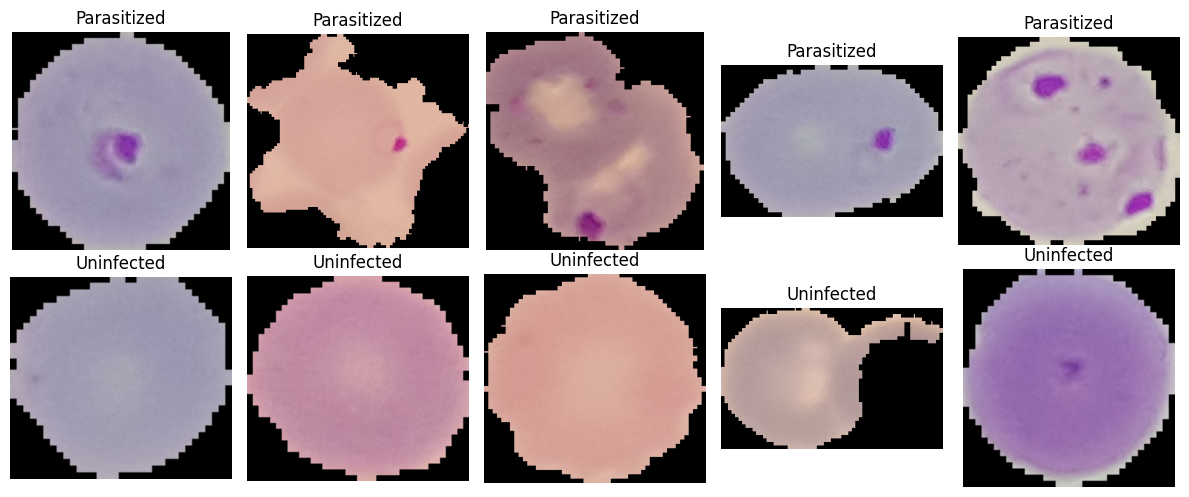

In [ ]:
plt.figure(figsize=(12, 5))

for i in range(5):
    image = plt.imread(os.path.join(parasitized_path, parasitized_images[i]))
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title("Parasitized")
    plt.axis("off")

    image = plt.imread(os.path.join(uninfected_path, uninfected_images[i]))
    plt.subplot(2, 5, i + 6)
    plt.imshow(image)
    plt.title("Uninfected")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Dataset Splitting

The dataset is divided into training and testing groups using an 80/20 ratio. Images from the same patient are kept together to prevent patient overlap between both groups.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

image_paths = []
labels = []
patient_ids = []

for class_name, label in [('Parasitized', 0), ('Uninfected', 1)]:
    folder = os.path.join(dataset_path, class_name)

    for file in os.listdir(folder):
        if file.endswith('.png'):
            image_paths.append(os.path.join(folder, file))
            labels.append(label)
            patient_ids.append(file.split('_IMG')[0])

image_paths = np.array(image_paths)
labels = np.array(labels)
patient_ids = np.array(patient_ids)

split = GroupShuffleSplit(
    test_size=0.20,
    n_splits=1,
    random_state=42
)

train_index, test_index = next(
    split.split(image_paths, labels, groups=patient_ids)
)

train_paths = image_paths[train_index]
test_paths = image_paths[test_index]

train_labels = labels[train_index]
test_labels = labels[test_index]

print("Training images:", len(train_paths))
print("Testing images:", len(test_paths))
print("Training patients:", len(np.unique(patient_ids[train_index])))
print("Testing patients:", len(np.unique(patient_ids[test_index])))

Training images: 21807
Testing images: 5751
Training patients: 160
Testing patients: 41


6. Verify the Dataset Splitting

In [ ]:
print("Patients in both groups:",
      len(set(patient_ids[train_index]) & set(patient_ids[test_index])))

Patients in both groups: 0


## 6. Image Preprocessing

All images are resized to 224 × 224 pixels and normalized to a range between 0 and 1.

This ensures that all images have the same dimensions and pixel intensity scale before being used by the CNN.

In [ ]:
def load_images(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(len(paths), seed=42)

    def preprocess(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_png(image, channels=3)
        image = tf.image.resize(image, (224, 224))
        image = image / 255.0
        return image, label

    dataset = dataset.map(preprocess)
    dataset = dataset.batch(32).prefetch(tf.data.AUTOTUNE)

    return dataset

train_dataset = load_images(train_paths, train_labels, training=True)
test_dataset = load_images(test_paths, test_labels)

print("Training dataset ready.")
print("Testing dataset ready.")

Training dataset ready.
Testing dataset ready.


## 7. Preprocessed Image Visualization

Sample images from the training dataset are displayed to verify that resizing and normalization were performed correctly.

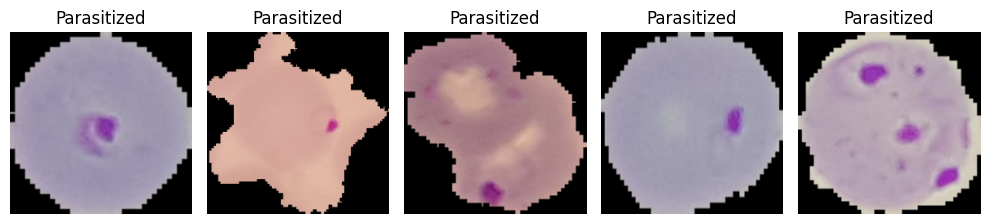

In [ ]:
class_names = ['Parasitized', 'Uninfected']

plt.figure(figsize=(10, 5))

for images_batch, labels_batch in train_dataset.take(1):
    for i in range(5):
        plt.subplot(1, 5, i + 1)
        plt.imshow(images_batch[i].numpy())
        plt.title(class_names[int(labels_batch[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()

## 8. CNN Model Architecture

A custom Convolutional Neural Network (CNN) is developed to classify blood cell images into two categories: Parasitized and Uninfected.

The model uses convolutional layers to extract image features, pooling layers to reduce dimensionality, and dense layers to perform the final classification.

In [ ]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 52, 52, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 60,545 (236.50 KB)

 Trainable params: 60,545 (236.50 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Model Compilation

The CNN model is compiled using the Adam optimizer and binary cross-entropy loss function. Accuracy is used to monitor the classification performance during training.

In [ ]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## 10. Model Training

The model is trained using the training dataset for 10 epochs. The testing dataset is used to evaluate its performance after each epoch.

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=test_dataset,
    callbacks=[early_stop]
)

Epoch 1/30
682/682 ━━━━━━━━━━━━━━━━━━━━ 42s 55ms/step - accuracy: 0.7619 - loss: 0.4815 - val_accuracy: 0.8665 - val_loss: 0.3416
Epoch 2/30
682/682 ━━━━━━━━━━━━━━━━━━━━ 35s 51ms/step - accuracy: 0.9347 - loss: 0.2024 - val_accuracy: 0.9231 - val_loss: 0.2351
Epoch 3/30
682/682 ━━━━━━━━━━━━━━━━━━━━ 35s 51ms/step - accuracy: 0.9391 - loss: 0.1960 - val_accuracy: 0.9245 - val_loss: 0.2213
Epoch 4/30
682/682 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.9444 - loss: 0.1755 - val_accuracy: 0.9310 - val_loss: 0.1990
Epoch 5/30
682/682 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step - accuracy: 0.9452 - loss: 0.1770 - val_accuracy: 0.9221 - val_loss: 0.2317
Epoch 6/30
682/682 ━━━━━━━━━━━━━━━━━━━━ 40s 58ms/step - accuracy: 0.9507 - loss: 0.1602 - val_accuracy: 0.9298 - val_loss: 0.2107
Epoch 7/30
682/682 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.9549 - loss: 0.1551 - val_accuracy: 0.9367 - val_loss: 0.1915
Epoch 8/30
682/682 ━━━━━━━━━━━━━━━━━━━━ 35s 51ms/step - accuracy: 0.9582 - loss: 0.1415 - 

## 11. Model Performance Visualization

Training and validation accuracy are plotted to visualize the learning process and evaluate the model's performance across the 10 epochs.

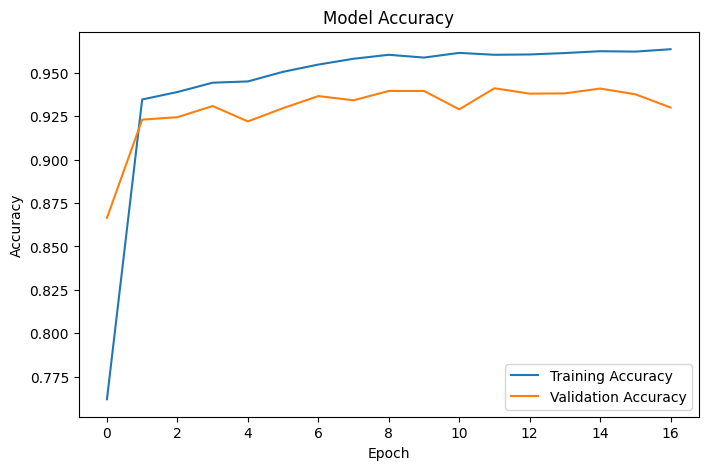

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

## 12. Model Loss Visualization

Training and validation loss are plotted to observe how the prediction error changes during training and to identify possible signs of overfitting.

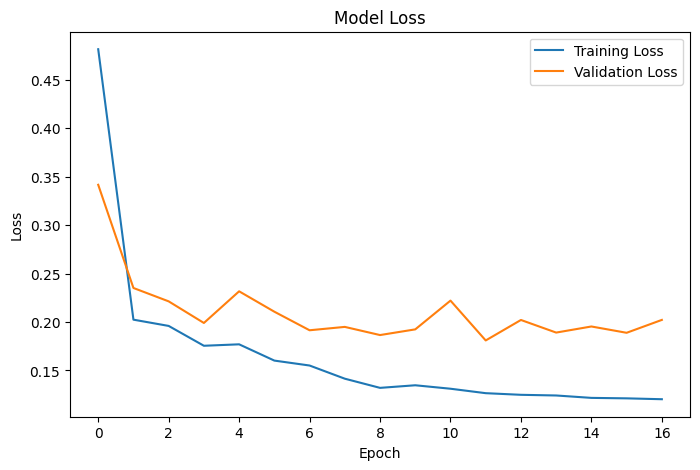

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## 13. Model Evaluation

The trained CNN is evaluated using the test dataset. Classification metrics are calculated to measure its performance in distinguishing between parasitized and uninfected cells.

The evaluation includes accuracy, precision, recall, F1-score, sensitivity, and specificity.

In [ ]:
predictions = model.predict(test_dataset)

predicted_labels = (predictions > 0.5).astype(int).flatten()

true_labels = test_labels

180/180 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step
